In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

df = pd.read_csv("data/power_toothbrush_users.csv")
df.columns = df.columns.str.strip()
df

,year,five_or_more_times,three_to_four_times,one_to_two_times,none,total_users_millions
0,2012,4.36,26.75,58.01,1.30,90.42
1,2013,4.39,26.94,58.54,1.31,91.18
2,2014,3.79,27.14,59.68,1.32,91.93
3,2015,3.97,27.90,65.37,1.31,98.55
4,2016,3.74,27.15,65.62,1.47,97.98
5,2017,3.88,30.16,72.46,1.16,107.66
6,2018,4.73,32.15,75.62,1.55,114.05
7,2019,4.50,33.03,80.30,1.32,119.15
8,2020,4.61,33.06,87.95,1.42,127.04



Innovation Diffusion Analysis Based on TIME's Best Innovations List
Meri Vlasyan

## Step 1. Chosen innovation
**Tilt Grip Stick** (TIME, The Best Inventions of 2025): <https://time.com/collections/best-inventions-2025/7318227/tilt-grip-stick/>

An adaptive lip balm for people with limited dexterity or chronic pain. It has an oversized grip, a magnetic closure and an easy-open tear strip, so it can be used one-handed. TIME reports it is the first lip product to earn the Arthritis Foundation's Ease of Use Certification.

## Step 2. Look-alike innovation: the power (electric) toothbrush

Both are personal-care products that improve a daily action through ergonomic design, and both were originally aimed at people with hand limitations. Mass production of power toothbrushes began in the 1960s, and they were recommended mainly for people with dexterity challenges. In 1990, Oral-B introduced its oscillating-rotating brush (Journal of the American Orthodontic Society, 2012), and by 2020 about 131 million Americans reported using a power toothbrush (Statista, 2020), far beyond the original group.

From a market standpoint, the Grip Stick may follow the same path of an assistive design becoming a mainstream product. It has a wide target audience: TIME reports that one in four U.S. adults lives with a disability, while only 4% of beauty brands cater to them. I use a category-level product, not a brand-level one like the Apple Watch, so the adoption pattern reflects need and usefulness rather than brand loyalty. The main difference is size: the power toothbrush is a much bigger and more mature market. I therefore use its diffusion pattern (p and q), but estimate the size of the Grip Stick’s market (M) separately in Step 7.



## Step 3. Historical data

**Source:** Statista (based on MRI-Simmons data), *U.S. population: Number of uses of a power toothbrush on an average day from 2012 to 2020*, ID 287374. Figures are millions of people in the U.S. among users of a power toothbrush.

The table splits users by brushing frequency. I add the four rows to get the **total number of power toothbrush users** per year (file: `data/power_toothbrush_users.csv`).

*Note:* the 2020 total here (127.04M) is slightly below the 131.43M in Statista's single-year table (ID 278156). These are different Statista tables, and I use the 2012-2020 series consistently.

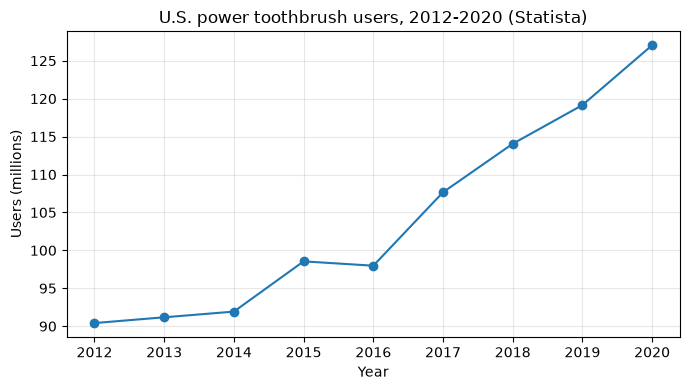

In [2]:
calc = df[["five_or_more_times","three_to_four_times","one_to_two_times","none"]].sum(axis=1).round(2)
assert (calc - df["total_users_millions"]).abs().max() < 0.01

plt.figure(figsize=(7,4))
plt.plot(df.year, df.total_users_millions, "o-")
plt.xlabel("Year"); plt.ylabel("Users (millions)")
plt.title("U.S. power toothbrush users, 2012-2020 (Statista)")
plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("img/toothbrush_users.png", dpi=150); plt.show()

## Step 4. Estimating the Bass parameters (p, q, M)

The Bass model for the **cumulative** number of adopters t years after launch is

$$N(t) = M\,\frac{1-e^{-(p+q)t}}{1+\frac{q}{p}e^{-(p+q)t}}$$

The data cover only 2012-2020, the middle of the curve, so p, q and M cannot all be estimated from it. I therefore make two assumptions:

1. **Launch year = 1990**, when Oral-B introduced the oscillating-rotating brush (Journal of the American Orthodontic Society, 2012). This is an assumption, and its effect is tested below.
2. **M is fixed** in two scenarios based on the 2020 Census: the population aged 18 and over (258.34 million) and the total population (331.45 million) (U.S. Census Bureau, 2021a, 2021b). p and q are then fitted by least squares.

In [3]:
def bass_cum(t, p, q, M):
    e = np.exp(-(p + q) * t)
    return M * (1 - e) / (1 + (q / p) * e)

LAUNCH = 1990
M_ADULTS = 258.34
M_TOTAL = 331.45
M_SCENARIOS = [M_ADULTS, M_TOTAL]
y = df.total_users_millions.values

def fit(M, launch=LAUNCH):
    tt = (df.year - launch).values
    f = lambda t_, p, q: bass_cum(t_, p, q, M)
    (p, q), _ = curve_fit(f, tt, y, p0=[0.005, 0.2], bounds=([1e-5, 1e-3], [0.5, 2]), maxfev=50000)
    resid = y - f(tt, p, q)
    rmse = np.sqrt((resid ** 2).mean())
    r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return p, q, rmse, r2

rows = []
for M in M_SCENARIOS:
    p, q, rmse, r2 = fit(M)
    rows.append(dict(M_millions=M, p=round(p, 4), q=round(q, 3), RMSE_millions=round(rmse, 2), R2=round(r2, 3)))
fits = pd.DataFrame(rows)
fits

,M_millions,p,q,RMSE_millions,R2
0,258.34,0.0105,0.051,3.22,0.935
1,331.45,0.0088,0.039,3.15,0.938


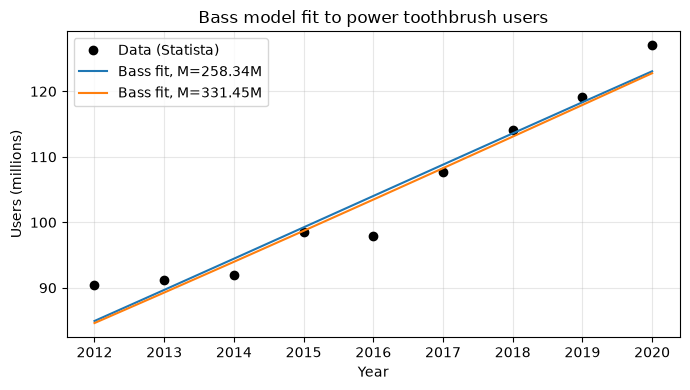

In [4]:
t = (df.year - LAUNCH).values
plt.figure(figsize=(7, 4))
plt.plot(df.year, y, "ko", label="Data (Statista)")
for r in rows:
    plt.plot(df.year, bass_cum(t, r["p"], r["q"], r["M_millions"]), label=f"Bass fit, M={r['M_millions']}M")
plt.xlabel("Year")
plt.ylabel("Users (millions)")
plt.title("Bass model fit to power toothbrush users")
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig("img/bass_fit.png", dpi=150)
plt.show()

In [5]:
rows2 = []
for L in [1985, 1990, 1992, 1995]:
    p, q, rmse, r2 = fit(M_ADULTS, launch=L)
    rows2.append(dict(launch_year=L, p=round(p, 4), q=round(q, 3), RMSE_millions=round(rmse, 2)))
pd.DataFrame(rows2)

,launch_year,p,q,RMSE_millions
0,1985,0.0064,0.061,3.14
1,1990,0.0105,0.051,3.22
2,1992,0.0130,0.045,3.27
3,1995,0.0182,0.032,3.36


**Reading the results.** The fit follows the data closely (error about 3% of the user count). The 2012-2020 series is close to a straight line, so q is low, and p and q change when M or the launch year changes. The parameters are therefore best read as a plausible range, not exact values.

## Step 5. Prediction approach

I predict the diffusion of the Grip Stick with the Bass model, using the p and q fitted on the power toothbrush (base case: M = 258.34 million) and a market potential M estimated separately for the Grip Stick in Step 7. Time t = 0 is the launch year, which I assume to be 2025, the year the Grip Stick appeared on TIME's Best Inventions list (published October 9, 2025). This is an assumption, because I did not find the exact launch date.

## Step 6. Scope: United States

I analyze the **United States**, for three reasons: (a) the look-alike data (Statista ID 287374) are for the U.S.; (b) the disability statistic in TIME (one in four adults) refers to U.S. adults; (c) official U.S. population figures are available (U.S. Census Bureau, 2021a, 2021b).

## Step 7. Market potential (M) of the Grip Stick: Fermi estimate

M = (U.S. lip care users) x (share with a disability) x (share who would buy a premium adaptive lip balm)

- **U.S. lip care users: 173.91 million** in 2020 (Statista, ID 276158, based on Census and MRI-Simmons data).
- **Share with a disability: 25%**, because TIME reports that one in four U.S. adults lives with a disability. This share is for adults, while the lip care users include all ages, so applying it to all users is an approximation.
- **Share who would buy: 5% (low), 10% (base), 20% (high).** No source exists for this number, so it is my assumption, and I show all three scenarios.

In [6]:
LIPCARE_USERS = 173.91
SHARE_DISABILITY = 0.25
SWITCH = {"low": 0.05, "base": 0.10, "high": 0.20}

M_GRIP = {k: LIPCARE_USERS * SHARE_DISABILITY * v for k, v in SWITCH.items()}
pd.DataFrame({"M_millions": M_GRIP}).round(2)

,M_millions
low,2.17
base,4.35
high,8.70


In [7]:
p_b, q_b = fit(M_ADULTS)[:2]

START = 2025
years = np.arange(START, START + 21)
t_end = years - START + 1
cum_adopters = bass_cum(t_end, p_b, q_b, M_GRIP["base"])
new_adopters = np.diff(np.concatenate([[0], cum_adopters]))

forecast = pd.DataFrame({
    "year": years,
    "new_adopters_thousands": (new_adopters * 1000).round(1),
    "cumulative_adopters_thousands": (cum_adopters * 1000).round(1),
})
forecast.to_csv("data/grip_stick_forecast.csv", index=False)
forecast

,year,new_adopters_thousands,cumulative_adopters_thousands
0,2025,46.6,46.6
1,2026,48.5,95.1
2,2027,50.4,145.4
3,2028,52.3,197.7
4,2029,54.2,251.9
5,2030,56.1,308.0
6,2031,58.0,366.0
7,2032,59.9,425.9
8,2033,61.8,487.7
9,2034,63.6,551.3


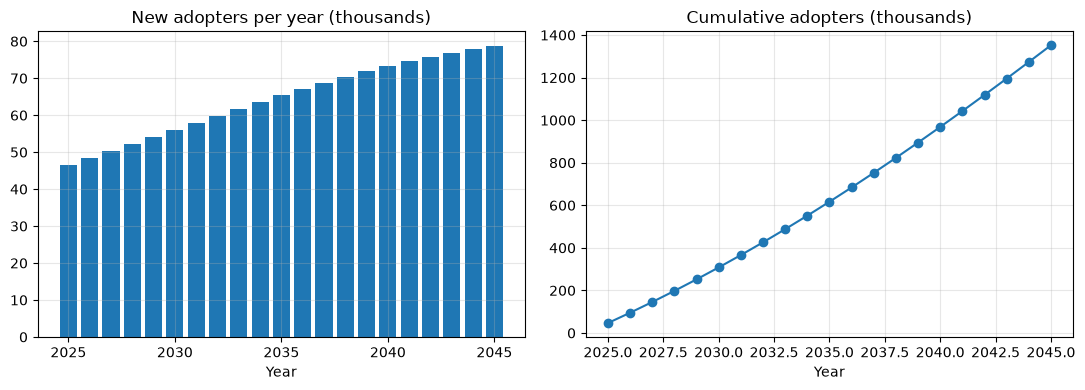

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(years, new_adopters * 1000)
ax[0].set_title("New adopters per year (thousands)")
ax[1].plot(years, cum_adopters * 1000, "o-")
ax[1].set_title("Cumulative adopters (thousands)")
for a in ax:
    a.set_xlabel("Year")
    a.grid(alpha=.3)
plt.tight_layout()
plt.savefig("img/grip_stick_forecast.png", dpi=150)
plt.show()

In [9]:
p_t, q_t = fit(M_TOTAL)[:2]
horizon = np.array([5, 10, 20])
res = {}
for name, M in M_GRIP.items():
    res[f"{name} M, p/q from adults"] = np.round(bass_cum(horizon, p_b, q_b, M) * 1000)
    res[f"{name} M, p/q from total pop."] = np.round(bass_cum(horizon, p_t, q_t, M) * 1000)
pd.DataFrame(res, index=["after 5 years", "after 10 years", "after 20 years"]).T

,after 5 years,after 10 years,after 20 years
"low M, p/q from adults",126.0,276.0,637.0
"low M, p/q from total pop.",103.0,221.0,498.0
"base M, p/q from adults",252.0,551.0,1274.0
"base M, p/q from total pop.",207.0,443.0,996.0
"high M, p/q from adults",504.0,1103.0,2547.0
"high M, p/q from total pop.",414.0,886.0,1991.0


## Discussion and limitations

- In the base case, the Grip Stick reaches about 252 thousand adopters after 5 years, 551 thousand after 10 years and 1.27 million after 20 years, which is about 29% of its market potential after 20 years. Adoption stays slow because the fitted q from the power toothbrush is low (the toothbrush series is almost a straight line in 2012-2020).
- The look-alike series covers only 2012-2020. The launch year (1990) and M were fixed by assumption, so p and q are a plausible range, not precise values.
- The Grip Stick's market potential is a Fermi estimate: the share of buyers (5%, 10%, 20%) is an assumption without a source, and the 25% disability share is for adults but is applied to users of all ages.
- The launch year of the Grip Stick (2025) is an assumption.
- The forecast is a scenario ("if the Grip Stick spreads like the power toothbrush did"), not a sales prediction.
- The Statista totals come from survey data and contain noise (for example, a dip in 2016).

## References

- Bass, F. M. (1969). A new product growth model for consumer durables. *Management Science, 15*(5), 215-227.
- Igneri, J. (2025, October 9). Tilt Grip Stick. *TIME, The Best Inventions of 2025.* https://time.com/collections/best-inventions-2025/7318227/tilt-grip-stick/
- Journal of the American Orthodontic Society. (2012, September-October). Power toothbrushes [Magazine article], p. 33. https://jaos.orthodontics.com/september-october-2012/page-33
- Statista (based on MRI-Simmons data). (2020). *U.S. population: Number of uses of a power toothbrush on an average day from 2012 to 2020* (ID 287374).
- Statista (based on MRI-Simmons data). (2020). *U.S. population: Do you use power toothbrushes?* (ID 278156).
- Statista (based on MRI-Simmons data). (2020). *U.S. population: Do you use lip care products?* (ID 276158).
- U.S. Census Bureau. (2021a, April 26). *2020 Census apportionment results delivered to the President* [Press release]. https://www.census.gov/newsroom/press-releases/2021/2020-census-apportionment-results.html
- U.S. Census Bureau. (2021b, August). *United States adult population grew faster than nation's total population from 2010 to 2020.* https://www.census.gov/library/stories/2021/08/united-states-adult-population-grew-faster-than-nations-total-population-from-2010-to-2020.html